In [68]:
import warnings

warnings.filterwarnings("ignore")

## Basic

In [69]:
import pandas as pd

df = pd.DataFrame([["a"], ["a"], ["a"], ["b"], ["b"], ["a"]], columns=["A"])
df

,A
0,a
1,a
2,a
3,b
4,b
5,a


In [70]:
df.groupby("A").cumcount()  # 각 그룹내에서 누적순번(0부터)을 매김

0    0
1    1
2    2
3    0
4    1
5    3
dtype: int64

In [71]:
old_feature_name_df = pd.DataFrame([["a"], ["a"], ["a"], ["b"], ["b"], ["a"]], columns=["column_name"])
old_feature_name_df

,column_name
0,a
1,a
2,a
3,b
4,b
5,a


In [72]:
feature_dup_df = pd.DataFrame(
    data=old_feature_name_df.groupby("column_name").cumcount(), columns=["dup_cnt"]
)

feature_dup_df

,dup_cnt
0,0
1,1
2,2
3,0
4,1
5,3


In [73]:
feature_dup_df = feature_dup_df.reset_index()
feature_dup_df

,index,dup_cnt
0,0,0
1,1,1
2,2,2
3,3,0
4,4,1
5,5,3


In [74]:
old_feature_name_df.reset_index()

,index,column_name
0,0,a
1,1,a
2,2,a
3,3,b
4,4,b
5,5,a


In [75]:
# merge : outer
new_feature_name_df = pd.merge(
    old_feature_name_df.reset_index(), feature_dup_df, how="outer"
)
new_feature_name_df

,index,column_name,dup_cnt
0,0,a,0
1,1,a,1
2,2,a,2
3,3,b,0
4,4,b,1
5,5,a,3


In [76]:
# axis=1 : 행에 대해서 lamba함수를 적용
new_feature_name_df["column_name"] = new_feature_name_df[["column_name", "dup_cnt"]
].apply(lambda x: x["column_name"] + "_" + str(x["dup_cnt"]) if x["dup_cnt"] > 0 else x["column_name"], axis=1) 

In [77]:
new_feature_name_df.head()

,index,column_name,dup_cnt
0,0,a,0
1,1,a_1,1
2,2,a_2,2
3,3,b,0
4,4,b_1,1


### 결정 트리 실습 - Human Activity Recognition

In [78]:
feature_name_df = pd.read_csv(
    "./human_activity/features.txt",
    sep="\s+",  # 하나이상의 공백을 구분자로 사용
    header=None,
    names=["column_index", "column_name"],
)
feature_name_df.head()

,column_index,column_name
0,1,tBodyAcc-mean()-X
1,2,tBodyAcc-mean()-Y
2,3,tBodyAcc-mean()-Z
3,4,tBodyAcc-std()-X
4,5,tBodyAcc-std()-Y


In [79]:
# 피처명 index를 제거하고, 피처명만 리스트 객체로 생성
feature_name = feature_name_df.iloc[:, 1].values.tolist()
print("전체 피처명에서 10개만 추출:", feature_name[:10])

전체 피처명에서 10개만 추출: ['tBodyAcc-mean()-X', 'tBodyAcc-mean()-Y', 'tBodyAcc-mean()-Z', 'tBodyAcc-std()-X', 'tBodyAcc-std()-Y', 'tBodyAcc-std()-Z', 'tBodyAcc-mad()-X', 'tBodyAcc-mad()-Y', 'tBodyAcc-mad()-Z', 'tBodyAcc-max()-X']


In [80]:
feature_dup_df = pd.DataFrame(
    data=feature_name_df.groupby("column_name").cumcount(), columns=["dup_cnt"]
)

feature_dup_df.head(10)

,dup_cnt
0,0
1,0
2,0
3,0
4,0
5,0
6,0
7,0
8,0
9,0


**중복된 피처명을 확인**

In [81]:
feature_dup_df = feature_name_df.groupby("column_name").count()
feature_dup_df

,column_index
column_name,
"angle(X,gravityMean)",1
"angle(Y,gravityMean)",1
"angle(Z,gravityMean)",1
"angle(tBodyAccJerkMean),gravityMean)",1
"angle(tBodyAccMean,gravity)",1
...,...
tGravityAccMag-max(),1
tGravityAccMag-mean(),1
tGravityAccMag-min(),1


In [82]:
print(feature_dup_df[feature_dup_df["column_index"] > 1].count())
feature_dup_df[feature_dup_df["column_index"] > 1].head()

column_index    42
dtype: int64


,column_index
column_name,
"fBodyAcc-bandsEnergy()-1,16",3
"fBodyAcc-bandsEnergy()-1,24",3
"fBodyAcc-bandsEnergy()-1,8",3
"fBodyAcc-bandsEnergy()-17,24",3
"fBodyAcc-bandsEnergy()-17,32",3


* get_new_feature_name_df() 생성

In [86]:
def get_new_feature_name_df(old_feature_name_df):
    feature_dup_df = pd.DataFrame(
        data=old_feature_name_df.groupby("column_name").cumcount(), \
        columns=["dup_cnt"]
    )
    feature_dup_df = feature_dup_df.reset_index()
    new_feature_name_df = pd.merge(
        old_feature_name_df.reset_index(), feature_dup_df, how="outer"
    )
    new_feature_name_df["column_name"] = new_feature_name_df[ ["column_name", "dup_cnt"]].apply(lambda x: x["column_name"] + "_" + str(x["dup_cnt"]) if x["dup_cnt"] > 0 else x["column_name"], axis=1)

    return new_feature_name_df

In [87]:
import pandas as pd

def get_human_dataset():
    feature_name_df = pd.read_csv(
        "./human_activity/features.txt",
        sep="\s+",
        header=None,
        names=["column_index", "column_name"],
    )

    # 신규 피처명 
    new_feature_name_df = get_new_feature_name_df(feature_name_df)

    # DataFrame에 피처명을 컬럼으로 부여하기 위해 리스트 객체로 다시 변환
    feature_name = new_feature_name_df.iloc[:, 1].values.tolist()

    # 학습 피처 데이터 셋과 테스트 피처 데이터을 DataFrame으로 로딩. 
    X_train = pd.read_csv(
        "./human_activity/train/X_train.txt", sep="\s+", names=feature_name
    )
    X_test = pd.read_csv(
        "./human_activity/test/X_test.txt", sep="\s+", names=feature_name
    )

    # 학습 레이블과 테스트 레이블 데이터을 DataFrame으로 로딩하고 
    # 컬럼명은 action으로 부여
    y_train = pd.read_csv(
        "./human_activity/train/y_train.txt", sep="\s+", header=None, 
        names=["action"]
    )
    y_test = pd.read_csv(
        "./human_activity/test/y_test.txt", sep="\s+", header=None,
        names=["action"]
    )

    return X_train, X_test, y_train, y_test

In [88]:
X_train, X_test, y_train, y_test = get_human_dataset()

In [89]:
print("## 학습 피처 데이터셋 info()")
print(X_train.info())

## 학습 피처 데이터셋 info()
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7352 entries, 0 to 7351
Columns: 561 entries, 1 to 561
dtypes: float64(561)
memory usage: 31.5 MB
None


In [90]:
print(y_train["action"].value_counts())

action
6    1407
5    1374
4    1286
1    1226
2    1073
3     986
Name: count, dtype: int64


In [93]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

dt_clf = DecisionTreeClassifier(random_state=156)
dt_clf.fit(X_train, y_train)
pred = dt_clf.predict(X_test)
accuracy = accuracy_score(y_test, pred)
print("결정 트리 예측 정확도: {0:.4f}".format(accuracy))

print("DecisionTreeClassifier 기본 하이퍼 파라미터:\n", dt_clf.get_params())

결정 트리 예측 정확도: 0.8548
DecisionTreeClassifier 기본 하이퍼 파라미터:
 {'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 156, 'splitter': 'best'}


In [95]:
from sklearn.model_selection import GridSearchCV

params = {"max_depth": [6, 8, 10, 12, 16, 20, 24]}

grid_cv = GridSearchCV(dt_clf, param_grid=params, scoring="accuracy", cv=5, verbose=1)
grid_cv.fit(X_train, y_train)
print("GridSearchCV 최고 평균 정확도 수치:{0:.4f}".format(grid_cv.best_score_))
print("GridSearchCV 최적 하이퍼 파라미터:", grid_cv.best_params_)

Fitting 5 folds for each of 7 candidates, totalling 35 fits
GridSearchCV 최고 평균 정확도 수치:0.8513
GridSearchCV 최적 하이퍼 파라미터: {'max_depth': 16}


In [96]:
cv_results_df = pd.DataFrame(grid_cv.cv_results_)
cv_results_df[["param_max_depth", "mean_test_score"]]

,param_max_depth,mean_test_score
0,6,0.850791
1,8,0.851069
2,10,0.851209
3,12,0.844135
4,16,0.851344
5,20,0.850800
6,24,0.849440


In [97]:
max_depths = [6, 8, 10, 12, 16, 20, 24]

for depth in max_depths:
    dt_clf = DecisionTreeClassifier(max_depth=depth, random_state=156)
    dt_clf.fit(X_train, y_train)
    pred = dt_clf.predict(X_test)
    accuracy = accuracy_score(y_test, pred)
    print("max_depth = {0} 정확도: {1:.4f}".format(depth, accuracy))

max_depth = 6 정확도: 0.8558
max_depth = 8 정확도: 0.8707
max_depth = 10 정확도: 0.8673
max_depth = 12 정확도: 0.8646
max_depth = 16 정확도: 0.8575
max_depth = 20 정확도: 0.8548
max_depth = 24 정확도: 0.8548


In [98]:
params = {
    "max_depth": [8, 12, 16, 20],
    "min_samples_split": [16, 24],
}

grid_cv = GridSearchCV(dt_clf, param_grid=params, scoring="accuracy", cv=5, verbose=1) # verbose : 0~3값
grid_cv.fit(X_train, y_train)
print("GridSearchCV 최고 평균 정확도 수치: {0:.4f}".format(grid_cv.best_score_))
print("GridSearchCV 최적 하이퍼 파라미터:", grid_cv.best_params_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
GridSearchCV 최고 평균 정확도 수치: 0.8549
GridSearchCV 최적 하이퍼 파라미터: {'max_depth': 8, 'min_samples_split': 16}


In [99]:
best_df_clf = grid_cv.best_estimator_
pred1 = best_df_clf.predict(X_test)
accuracy = accuracy_score(y_test, pred1)
print("결정 트리 예측 정확도:{0:.4f}".format(accuracy))

결정 트리 예측 정확도:0.8717


Index([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,
       ...
       552, 553, 554, 555, 556, 557, 558, 559, 560, 561],
      dtype='int64', length=561)


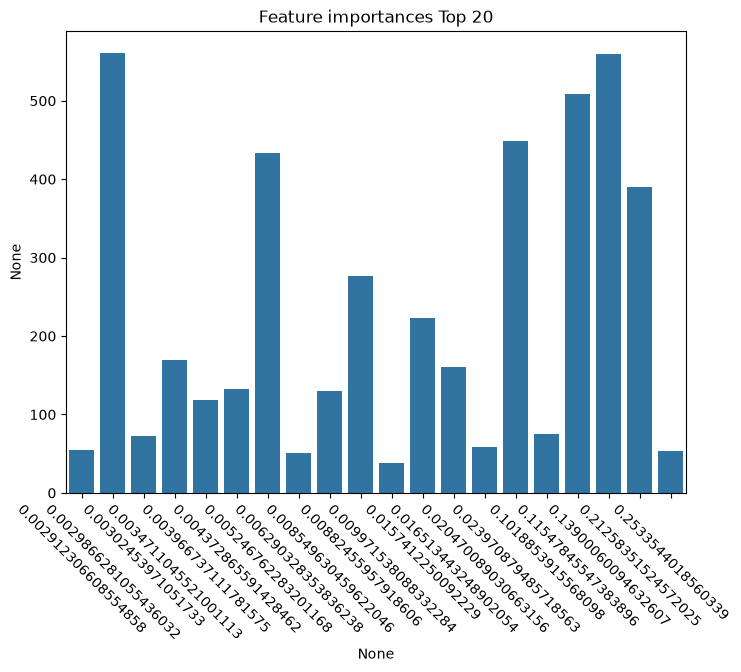

In [101]:
import seaborn as sns
import matplotlib.pyplot as plt

ftr_importances_values = best_df_clf.feature_importances_
ftr_importances = pd.Series(ftr_importances_values, index=X_train.columns )

# 중요도값 순으로 Series를 정렬
ftr_top20 = ftr_importances.sort_values(ascending=False)[:20]
print(X_train.columns)

plt.figure(figsize=(8,6))
plt.title('Feature importances Top 20')
plt.xticks(rotation = -45)
sns.barplot(x=ftr_top20 , y = ftr_top20.index)
plt.show()
